# Sidewalk classifiers from scratch: two independent CNNs

This separate companion to the frozen-DINO notebook trains **one randomly initialized RegNetY-400MF per task**:
1. **Hazard:** Obstacle + SurfaceProblem versus Crosswalk + CurbRamp + no_obstacles.
2. **Subtype:** Obstacle versus SurfaceProblem, trained and scored on **true hazards only**.

Every parameter is trainable; `weights=None` means no pretrained backbone or feature cache.
Keep the original validation protocol: `pitt-val`, **Recall@44** for stage 1, and stage-2 balanced accuracy
independent of stage-1 errors. `pitt-test` is not read by training, tuning, or evaluation.

The default is **two models total**, each with a **20-minute budget** for construction, training, periodic validation,
and checkpointing. Data setup and final reporting are outside the budget; final saving can add a little time.
Expect approximately 40 minutes plus setup. Start with **Run All** on a Colab T4 kernel and authorize Drive.
Provide HF_TOKEN through an environment variable or Colab Secrets, or enter the read token at the hidden prompt.

All results go to `MyDrive/MLiP/scratch_classifiers/<run-id>/`. There is no fallback to ephemeral result storage.
The training engine is embedded below, so no server-local Python module is required in Colab.


## Runtime: select Colab → T4 GPU


In [12]:
import importlib.util, subprocess, sys

# Keep Colab's matching torch/torchvision/CUDA installation; do not upgrade it here.
required = {'huggingface_hub': 'huggingface_hub', 'pandas': 'pandas',
            'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib'}
missing = [distribution for module, distribution in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import torch, torchvision
if not torch.cuda.is_available():
    raise RuntimeError('Select a Colab GPU/T4 kernel. Do not run this experiment on the server CPU kernel.')
device = torch.device('cuda')
torch.backends.cudnn.benchmark = True
print('torch', torch.__version__, '| torchvision', torchvision.__version__)
print('GPU:', torch.cuda.get_device_name(0), '| memory GiB:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
print('Precision: FP16 AMP (T4), not BF16. No torch.compile startup cost.')


torch 2.11.0+cu130 | torchvision 0.26.0+cu130
GPU: Tesla T4 | memory GiB: 14.6
Precision: FP16 AMP (T4), not BF16. No torch.compile startup cost.


## Configuration and bounded sweeps

The default training plan spends 75% of its update window on other cities and 25% on Pittsburgh.
Each task has its own network, optimizer, class weights, validation-selected checkpoint, and deadline.
`SWEEPS` is deliberately a singleton by default. Adding architectures, learning rates, plans, or seeds creates
additional pairs of models at 40 minutes per configuration. Threshold sweeps reuse saved probabilities and do not retrain.
Keep `K=44` to compare with the original notebook. Headline subtype accuracy includes every true validation hazard.


In [13]:
from pathlib import Path
from itertools import product

DATA_REPO = 'gvadhul/sidewalk-proc-A-naive-merged-nulls'
DATA_TAR = 'proc-sidewalk-data-naive-merged-nulls.tar'
DATA_ROOT = Path('/content/proc-sidewalk-data-naive-merged-nulls')
DRIVE_ROOT = Path('/content/drive/MyDrive/MLiP/scratch_classifiers')
RESUME_RUN_DIR = None  # After reconnecting, set this to an existing Drive run directory.
EVAL_SPLIT = 'pitt-val'
K = 44
THRESHOLDS = [0.3, 0.5, 0.7]
TRAIN_PLANS = {
    'pitt': [('pitt-train', 1.0)],
    'other_then_pitt': [('other-cities-train', 0.75), ('pitt-train', 0.25)],
}
BASE = dict(architecture='regnet_y_400mf', train='other_then_pitt', lr=1e-3,
            weight_decay=1e-4, batch_size=128, eval_batch_size=128, num_workers=2,
            budget_seconds=20 * 60, finalize_reserve_seconds=30, eval_seconds=90,
            warmup_steps=20, pitt_lr_factor=0.3, grad_clip=1.0, seed=0, max_steps=None)
SWEEPS = [dict(architecture=['regnet_y_400mf'], train=['other_then_pitt'], lr=[1e-3], seed=[0])]
CONFIGS = [{**BASE, **dict(zip(sweep, values))} for sweep in SWEEPS for values in product(*sweep.values())]
assert CONFIGS and EVAL_SPLIT == 'pitt-val' and K >= 1 and 0.5 in THRESHOLDS
for cfg in CONFIGS:
    assert cfg['train'] in TRAIN_PLANS and cfg['budget_seconds'] > cfg['finalize_reserve_seconds']
print(len(CONFIGS), 'configurations ->', 2 * len(CONFIGS), 'independent models')
print('Configured model budgets total:', sum(2 * cfg['budget_seconds'] for cfg in CONFIGS) / 60, 'minutes, plus setup/final saves')

# Fingerprints of the current processed dataset on sidewalk-cpu. Stop on an outdated private archive.
EXPECTED_MANIFEST_SHA256 = {
    'other-cities-train': '57e004a3b6d9e5f0482be285f8bea920b371428caf4fe9ab6c44c13ef9af19a2',
    'pitt-train': '081723b38ebf0b5448d56e67be6b0c99dafdf2e3cf239e7d7a239b5fcfaad0cf',
    'pitt-val': 'ae5cc3b382794050c8ad92dcb28ea1a4b82240ed266d329404a67e791a5e69de',
}
EXPECTED_COUNTS = {'other-cities-train': 22912, 'pitt-train': 999, 'pitt-val': 382}


1 configurations -> 2 independent models
Configured model budgets total: 40.0 minutes, plus setup/final saves


## Mount Google Drive before spending GPU time

Current Colab VS Code extensions support `drive.mount()` (since v0.2.1); the server has v0.9.7.
Authorize the mount when prompted. If the prompt is missing, use **Colab: Mount Google Drive to Server...**
in the command palette, or run the notebook in Colab's browser UI. The cell stops if Drive is unavailable.
See the [official extension guide](https://github.com/googlecolab/colab-vscode/wiki/User-Guide#mounting-google-drive)
and [support notes](https://github.com/googlecolab/colab-vscode/wiki/Known-Issues-and-Workarounds#drivemount).


In [14]:
import json, os, uuid
from datetime import datetime, timezone
try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError('Run this notebook on a hosted Colab kernel with Drive support.') from exc
drive.mount('/content/drive')
if not Path('/content/drive/MyDrive').is_dir():
    raise RuntimeError('Google Drive did not mount; training is stopped to avoid losing outputs.')
DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
probe = DRIVE_ROOT / ('.write-check-' + uuid.uuid4().hex)
probe.write_text('drive write verified')
assert probe.read_text() == 'drive write verified'
probe.unlink()
if RESUME_RUN_DIR:
    RUN_DIR = Path(RESUME_RUN_DIR)
    if not RUN_DIR.is_dir() or not RUN_DIR.resolve().is_relative_to(DRIVE_ROOT.resolve()):
        raise ValueError('RESUME_RUN_DIR must be an existing run under DRIVE_ROOT.')
else:
    RUN_DIR = DRIVE_ROOT / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + uuid.uuid4().hex[:6])
    RUN_DIR.mkdir()
print('Persistent output directory:', RUN_DIR)
print('To resume after a runtime reset, set RESUME_RUN_DIR to this path and rerun the notebook.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent output directory: /content/drive/MyDrive/MLiP/scratch_classifiers/20261031T022348Z-c27d49
To resume after a runtime reset, set RESUME_RUN_DIR to this path and rerun the notebook.


## Data: the existing private Hugging Face archive, local Colab SSD

Set `HF_TOKEN` in the environment or Colab Secrets. If neither is available, the data cell asks for a read token using a hidden prompt.
The token is not copied into training-result artifacts.
Use local SSD for input images and Drive for outputs. The three loaded CSVs must match the current server dataset exactly;
if the private archive is older, update that archive before running. Their original annotations and source classes are retained.


In [15]:
import getpass, hashlib, os, shutil, tarfile, time
import numpy as np, pandas as pd
from huggingface_hub import HfApi, hf_hub_download

SPLITS = sorted({split for cfg in CONFIGS for split, _ in TRAIN_PLANS[cfg['train']]} | {EVAL_SPLIT})
assert 'pitt-test' not in SPLITS
# Use a runtime credential; do not store it in the notebook.
HF_TOKEN = os.environ.get('HF_TOKEN', '').strip()
download_info = {'repo': DATA_REPO, 'archive': DATA_TAR, 'source': 'existing Colab data directory'}
if not all((DATA_ROOT / f'{split}.csv').is_file() for split in SPLITS):
    if not HF_TOKEN:
        try:
            from google.colab import userdata
            HF_TOKEN = (userdata.get('HF_TOKEN') or '').strip()
        except Exception:
            HF_TOKEN = ''
    if not HF_TOKEN:
        HF_TOKEN = getpass.getpass('Hugging Face read token: ').strip()
    if not HF_TOKEN:
        raise RuntimeError('Provide an HF_TOKEN that can read the private dataset.')
    started = time.perf_counter()
    revision = HfApi(token=HF_TOKEN).dataset_info(DATA_REPO).sha
    archive_path = Path(hf_hub_download(DATA_REPO, DATA_TAR, repo_type='dataset', revision=revision, token=HF_TOKEN))
    with tarfile.open(archive_path) as archive:
        archive.extractall(DATA_ROOT.parent, filter='data')
    with archive_path.open('rb') as archive_stream:
        archive_sha = hashlib.file_digest(archive_stream, 'sha256').hexdigest()
    download_info.update(source='Hugging Face download', revision=revision, archive_sha256=archive_sha)
    (DATA_ROOT / '.colab_source.json').write_text(json.dumps(download_info, indent=2))
    print(f'Downloaded/extracted in {time.perf_counter() - started:.0f}s')
elif (DATA_ROOT / '.colab_source.json').exists():
    download_info.update(json.loads((DATA_ROOT / '.colab_source.json').read_text()))

data, manifest_info = {}, {}
for split in SPLITS:
    manifest = DATA_ROOT / f'{split}.csv'
    digest = hashlib.sha256(manifest.read_bytes()).hexdigest()
    if digest != EXPECTED_MANIFEST_SHA256[split]:
        raise RuntimeError(f'{split}.csv does not match the requested server dataset. Update the private HF archive or existing DATA_ROOT; do not silently train on another version.')
    frame = pd.read_csv(manifest, low_memory=False)
    assert len(frame) == EXPECTED_COUNTS[split] and frame['split'].eq(split).all()
    assert frame.image_path.is_unique
    for image_path, label in zip(frame.image_path, frame['class']):
        relative = Path(image_path)
        assert len(relative.parts) == 3 and relative.parts[:2] == (split, label)
        assert (DATA_ROOT / relative).is_file(), relative
    data[split] = frame
    manifest_info[split] = {'sha256': digest, 'images': len(frame), 'class_counts': frame['class'].value_counts().to_dict()}
    (RUN_DIR / 'manifests').mkdir(exist_ok=True)
    snapshot = RUN_DIR / 'manifests' / manifest.name
    if snapshot.exists():
        assert hashlib.sha256(snapshot.read_bytes()).hexdigest() == digest, 'Resume manifest differs from the saved snapshot.'
    else:
        shutil.copy2(manifest, snapshot)
    print(split, len(frame), frame['class'].value_counts().to_dict())
DATA_FINGERPRINT = hashlib.sha256(json.dumps(manifest_info, sort_keys=True).encode()).hexdigest()
dataset_config = DATA_ROOT / 'config.yaml'
if dataset_config.is_file():
    snapshot = RUN_DIR / 'dataset_config.yaml'
    if snapshot.exists():
        assert snapshot.read_bytes() == dataset_config.read_bytes(), 'Resume preprocessing configuration changed.'
    else:
        shutil.copy2(dataset_config, snapshot)
print('Loaded splits:', SPLITS, '| stage 1 positive = Obstacle + SurfaceProblem')


proc-sidewalk-data-naive-merged-nulls.ta(…): reconstructing file:   0%|          |  0.00B / 2.29GB            

proc-sidewalk-data-naive-merged-nulls.ta(…): downloading bytes:           |  0.00B            

Downloaded/extracted in 41s
other-cities-train 22912 {'CurbRamp': 10096, 'SurfaceProblem': 8521, 'Obstacle': 2376, 'Crosswalk': 1570, 'no_obstacles': 349}
pitt-train 999 {'CurbRamp': 457, 'SurfaceProblem': 389, 'no_obstacles': 80, 'Obstacle': 39, 'Crosswalk': 34}
pitt-val 382 {'CurbRamp': 152, 'SurfaceProblem': 124, 'no_obstacles': 81, 'Obstacle': 14, 'Crosswalk': 11}
Loaded splits: ['other-cities-train', 'pitt-train', 'pitt-val'] | stage 1 positive = Obstacle + SurfaceProblem


## Model and training implementation

[RegNetY-400MF](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.regnet_y_400mf.html)
is a compact convolutional model (the standard ImageNet version is about 4.3M parameters and 0.40 GFLOPs).
It is a practical choice for learning from scratch under this short budget; it is **not a measured optimum on this dataset**.
Actual T4 throughput, completed updates, and validation scores are logged. A larger transformer would spend more of the budget
per update without pretrained features. `resnet18` is available as an optional sweep alternative.

Training uses AdamW, FP16 AMP, channels-last layout, per-phase class-weighted cross-entropy, horizontal flips and mild
per-image color jitter. Full scenes are kept: no random crop removes the annotated feature. Every layer learns.
Learning rate warms up and follows wall-clock cosine decay in each phase, with a lower LR for Pittsburgh adaptation.

Checkpoints/history go to Drive every 90 seconds and at the end. `best.pt` is selected by validation Recall@44 for hazard
or validation balanced accuracy at 0.5 for subtype, with average precision breaking ties. Stage 2 scores all true hazards
regardless of stage-1 predictions. The code reserves 30 seconds for finalization and stops new updates at the time limit;
an in-flight batch and Drive writes can add a little overhead. No T4 benchmark has been run from this server.


In [16]:
%%writefile /content/sidewalk_scratch_engine.py
"""Two independent image classifiers, random initialization, bounded GPU training."""
from pathlib import Path
from datetime import datetime, timezone
import contextlib
import hashlib
import json
import math
import os
import random
import shutil
import tempfile
import time

import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from sklearn.metrics import (accuracy_score, average_precision_score,
                             balanced_accuracy_score, confusion_matrix,
                             precision_recall_fscore_support)

PROBLEMS = {'Obstacle', 'SurfaceProblem'}
ALLOWED_CLASSES = PROBLEMS | {'Crosswalk', 'CurbRamp', 'no_obstacles', 'no_obstacles_manual_collection'}
TASKS = ('hazard', 'subtype')


def utc_now():
    return datetime.now(timezone.utc).isoformat()


def json_text(value):
    return json.dumps(value, indent=2, allow_nan=False, default=lambda v: v.item() if isinstance(v, np.generic) else str(v)) + '\n'


def atomic_text(path, text):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name('.' + path.name + '.tmp')
    with temporary.open('w', encoding='utf-8') as stream:
        stream.write(text)
        stream.flush()
    os.replace(temporary, path)


def save_json(path, value):
    atomic_text(path, json_text(value))


def save_csv(path, frame):
    atomic_text(path, frame.to_csv(index=False))


def save_checkpoint(path, state):
    """Serialize locally, then publish a complete checkpoint to mounted Drive."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix='sidewalk-checkpoint-') as temporary:
        local = Path(temporary) / path.name
        torch.save(state, local)
        remote_temporary = path.with_name('.' + path.name + '.tmp')
        shutil.copyfile(local, remote_temporary)
        os.replace(remote_temporary, path)


def checkpoint_load(path):
    # Only load checkpoints written by this experiment, never downloaded model weights.
    return torch.load(path, map_location='cpu', weights_only=False)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def rng_state():
    return {'python': random.getstate(), 'numpy': np.random.get_state(),
            'torch': torch.get_rng_state(),
            'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'])
    if state['cuda'] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state['cuda'])


def make_model(architecture):
    constructors = {'regnet_y_400mf': models.regnet_y_400mf, 'resnet18': models.resnet18}
    if architecture not in constructors:
        raise ValueError(f'Unsupported architecture: {architecture}')
    model = constructors[architecture](weights=None, num_classes=2)
    assert all(parameter.requires_grad for parameter in model.parameters())
    return model


def task_frame(frame, task, training=False):
    if task not in TASKS:
        raise ValueError(f'Unknown task: {task}')
    frame = frame.copy()
    unknown = set(frame['class']) - ALLOWED_CLASSES
    if unknown:
        raise ValueError(f'Unknown dataset classes: {unknown}')
    frame['is_problem'] = frame['class'].isin(PROBLEMS)
    frame['is_obstacle'] = frame['class'].eq('Obstacle')
    if task == 'subtype' and training:
        frame = frame[frame.is_problem].copy()
    frame['target'] = (frame.is_problem if task == 'hazard' else frame.is_obstacle).astype('int64')
    return frame.reset_index(drop=True)


class ImageRows(Dataset):
    def __init__(self, frame, root):
        self.frame = frame.reset_index(drop=True)
        self.root = Path(root).resolve()

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        path = (self.root / row.image_path).resolve()
        if not path.is_relative_to(self.root):
            raise ValueError(f'Image path leaves dataset: {row.image_path}')
        with Image.open(path) as image:
            if image.size != (224, 224):
                raise ValueError(f'Expected stored 224x224 image, got {image.size}: {path}')
            array = np.array(image.convert('RGB'), dtype=np.uint8, copy=True)
        return torch.from_numpy(array).permute(2, 0, 1), int(row.target)


def prepare_batch(batch, device, training=False):
    """Light per-image augmentation on GPU; keep the entire annotated scene."""
    x = batch.to(device, non_blocking=True, memory_format=torch.channels_last).float().div_(255)
    if training:
        shape = (len(x), 1, 1, 1)
        flip = torch.rand(shape, device=device) < 0.5
        x = torch.where(flip, x.flip(-1), x)
        brightness = torch.empty(shape, device=device).uniform_(0.8, 1.2)
        contrast = torch.empty(shape, device=device).uniform_(0.8, 1.2)
        saturation = torch.empty(shape, device=device).uniform_(0.85, 1.15)
        x = x * brightness
        mean = x.mean((1, 2, 3), keepdim=True)
        x = (x - mean) * contrast + mean
        gray = x.mean(1, keepdim=True)
        x = ((x - gray) * saturation + gray).clamp_(0, 1)
    mean = x.new_tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = x.new_tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    return ((x - mean) / std).contiguous(memory_format=torch.channels_last)


def autocast_context(device):
    # T4 supports FP16; do not request BF16 as the frozen-feature notebook did.
    return torch.autocast('cuda', dtype=torch.float16) if device.type == 'cuda' else contextlib.nullcontext()


@torch.inference_mode()
def predict(model, loader, device):
    model.eval()
    probabilities = []
    for batch, _ in loader:
        x = prepare_batch(batch, device)
        with autocast_context(device):
            logits = model(x)
        probabilities.append(logits.float().softmax(1)[:, 1].cpu().numpy())
    return np.concatenate(probabilities)


def task_metrics(frame, probability, task, k, threshold):
    if (len(frame) != len(probability) or not np.isfinite(probability).all()
            or np.any(probability < 0) or np.any(probability > 1) or k < 1):
        raise ValueError('Invalid probability vector')
    truth = frame['class'].isin(PROBLEMS).to_numpy()
    if task == 'hazard':
        target = truth
        selected = np.argsort(-probability, kind='stable')[:min(k, len(frame))]
        count = int(target[selected].sum())
        total = int(target.sum())
        metrics = {f'recall@{k}': count / total, f'precision@{k}': count / len(selected),
                   f'recall@{k}_cap': min(k, total) / total, 'hazards_in_top_k': count}
    else:
        target = frame.loc[truth, 'class'].eq('Obstacle').to_numpy()
        probability = probability[truth]
        metrics = {}
    predicted = probability >= threshold
    precision, recall, f1, support = precision_recall_fscore_support(
        target, predicted, labels=[False, True], zero_division=0)
    metrics.update(accuracy=float(accuracy_score(target, predicted)),
                   balanced_accuracy=float(balanced_accuracy_score(target, predicted)),
                   average_precision=float(average_precision_score(target, probability)),
                   macro_f1=float(f1.mean()), threshold=float(threshold), n_evaluated=len(target),
                   negative_recall=float(recall[0]), positive_recall=float(recall[1]),
                   negative_precision=float(precision[0]), positive_precision=float(precision[1]),
                   negative_support=int(support[0]), positive_support=int(support[1]))
    metrics['confusion'] = confusion_matrix(target, predicted, labels=[False, True]).tolist()
    return metrics


def selection_score(metrics, task, k):
    return (metrics[f'recall@{k}'] if task == 'hazard' else metrics['balanced_accuracy'],
            metrics['average_precision'])


def run_model(cfg, task, frames, data_root, run_root, plan, data_fingerprint, device,
              k=44, thresholds=(0.3, 0.5, 0.7), eval_split='pitt-val'):
    """One end-to-end CNN, at most cfg['budget_seconds'] per saved model run."""
    device = torch.device(device)
    identity = {'config': cfg, 'task': task, 'plan': plan, 'data_fingerprint': data_fingerprint,
                'k': k, 'thresholds': list(thresholds), 'eval_split': eval_split,
                'engine_sha256': hashlib.sha256(Path(__file__).read_bytes()).hexdigest()}
    identity_hash = hashlib.sha256(json_text(identity).encode()).hexdigest()
    directory = Path(run_root) / f"{cfg['architecture']}_{cfg['train']}_lr{cfg['lr']:g}_seed{cfg['seed']}_{task}_{identity_hash[:8]}"
    directory.mkdir(parents=True, exist_ok=True)
    if (directory / 'identity.json').exists():
        if json.loads((directory / 'identity.json').read_text()) != identity:
            # JSON roundtrips tuples as lists; compare the canonical form.
            assert (directory / 'identity.json').read_text() == json_text(identity), 'Resume configuration changed'
    else:
        save_json(directory / 'identity.json', identity)
    if (directory / 'summary.json').exists():
        summary = json.loads((directory / 'summary.json').read_text())
        if summary.get('status') == 'complete':
            print(f'Skipping completed {directory.name}', flush=True)
            return summary

    seed_everything(cfg['seed'])
    started = time.perf_counter()
    spent_before = 0.0
    step = 0
    examples_seen = 0
    best_score = (-1.0, -1.0)
    best_step = None
    phase_index = -1
    phase_step = 0
    history_path = directory / 'history.jsonl'
    history = [json.loads(line) for line in history_path.read_text().splitlines()] if history_path.exists() else []
    model = make_model(cfg['architecture']).to(device, memory_format=torch.channels_last)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    rng = torch.Generator().manual_seed(cfg['seed'])
    if (directory / 'last.pt').exists():
        saved = checkpoint_load(directory / 'last.pt')
        assert saved['identity_hash'] == identity_hash, 'Checkpoint/config mismatch'
        model.load_state_dict(saved['model'])
        optimizer.load_state_dict(saved['optimizer'])
        scaler.load_state_dict(saved['scaler'])
        step, examples_seen = saved['step'], saved['examples_seen']
        spent_before = saved['elapsed_seconds']
        best_score, best_step = tuple(saved['best_score']), saved['best_step']
        phase_index, phase_step = saved['phase_index'], saved['phase_step']
        rng.set_state(saved['loader_rng'])
        restore_rng(saved['rng'])
        progress_path = directory / 'progress.json'
        if progress_path.exists():
            progress = json.loads(progress_path.read_text())
            if progress.get('checkpoint_step') == step:
                spent_before = max(spent_before, progress['elapsed_seconds'])
        # Keep only records represented by this checkpoint if a write was interrupted.
        history = [row for row in history if row['step'] <= step]
        atomic_text(history_path, ''.join(json.dumps(row) + '\n' for row in history))
        print(f'Resuming {task}: step {step}, {spent_before:.0f}s already spent', flush=True)

    def elapsed():
        return spent_before + time.perf_counter() - started

    budget = float(cfg['budget_seconds'])
    train_until = max(0.0, budget - cfg['finalize_reserve_seconds'])
    durations = np.array([float(fraction) for _, fraction in plan])
    assert np.all(durations > 0) and math.isclose(float(durations.sum()), 1.0)
    boundaries = np.cumsum(durations) * train_until
    val_frame = task_frame(frames[eval_split], task)
    val_loader = DataLoader(ImageRows(val_frame, data_root), batch_size=cfg['eval_batch_size'],
                            shuffle=False, num_workers=0, pin_memory=device.type == 'cuda')
    loader = iterator = None
    active_phase = None
    class_weights = None
    last_evaluation = elapsed()
    loss_window = []

    def checkpoint_and_evaluate(phase_name):
        nonlocal best_score, best_step, last_evaluation
        probability = predict(model, val_loader, device)
        metrics = task_metrics(val_frame, probability, task, k, 0.5)
        score = selection_score(metrics, task, k)
        if score > best_score:
            best_score, best_step = score, step
            save_checkpoint(directory / 'best.pt', {'identity_hash': identity_hash,
                'model': {key: value.detach().cpu() for key, value in model.state_dict().items()},
                'config': cfg, 'task': task, 'step': step, 'metrics': metrics})
        row = {'utc': utc_now(), 'task': task, 'step': step, 'phase': phase_name,
               'elapsed_seconds': elapsed(), 'examples_seen': examples_seen,
               'train_loss': float(np.mean(loss_window)) if loss_window else None,
               'lr': optimizer.param_groups[0]['lr'], **metrics}
        history.append(row)
        atomic_text(history_path, ''.join(json.dumps(item) + '\n' for item in history))
        save_csv(directory / 'history.csv', pd.DataFrame([{k: v for k, v in r.items() if k != 'confusion'} for r in history]))
        save_checkpoint(directory / 'last.pt', {'identity_hash': identity_hash,
            'model': model.state_dict(), 'optimizer': optimizer.state_dict(), 'scaler': scaler.state_dict(),
            'rng': rng_state(), 'loader_rng': rng.get_state(), 'step': step,
            'phase_index': phase_index, 'phase_step': phase_step, 'examples_seen': examples_seen,
            'elapsed_seconds': elapsed(), 'best_score': best_score, 'best_step': best_step})
        save_json(directory / 'progress.json', {'status': 'running', 'checkpoint_step': step,
                                               'elapsed_seconds': elapsed(), 'budget_seconds': budget,
                                               'best_step': best_step, 'utc': utc_now()})
        last_evaluation = elapsed()
        loss_window.clear()
        print(f"{task} | {phase_name} | step {step} | {elapsed():.0f}/{budget:.0f}s | "
              f"selection={score[0]:.4f} | val balanced={metrics['balanced_accuracy']:.4f}", flush=True)
        return probability

    try:
        while elapsed() < train_until and (cfg.get('max_steps') is None or step < cfg['max_steps']):
            desired_phase = min(int(np.searchsorted(boundaries, elapsed(), side='right')), len(plan) - 1)
            if active_phase != desired_phase:
                previous_phase = phase_index
                phase_index = desired_phase
                if active_phase is not None or previous_phase != desired_phase:
                    phase_step = 0
                if loader is not None:
                    del iterator, loader
                split = plan[phase_index][0]
                train_frame = task_frame(frames[split], task, training=True)
                counts = np.bincount(train_frame.target, minlength=2)
                if not np.all(counts > 0):
                    raise ValueError(f'{task}/{split} needs both classes: {counts}')
                class_weights = torch.tensor(len(train_frame) / (2 * counts), dtype=torch.float32, device=device)
                loader = DataLoader(ImageRows(train_frame, data_root), batch_size=cfg['batch_size'],
                                    shuffle=True, generator=rng, num_workers=cfg['num_workers'],
                                    pin_memory=device.type == 'cuda', drop_last=False,
                                    persistent_workers=cfg['num_workers'] > 0)
                iterator = iter(loader)
                active_phase = phase_index
                print(f'{task}: {split}, {len(train_frame)} images, class counts {counts.tolist()}', flush=True)
            try:
                batch, target = next(iterator)
            except StopIteration:
                iterator = iter(loader)
                batch, target = next(iterator)
            # Recheck after disk loading; do not start another update past the deadline.
            if elapsed() >= train_until:
                break
            if len(target) < 2:
                continue
            phase_begin = 0.0 if phase_index == 0 else boundaries[phase_index - 1]
            fraction = min(1.0, max(0.0, (elapsed() - phase_begin) / (boundaries[phase_index] - phase_begin)))
            scale = cfg['pitt_lr_factor'] if plan[phase_index][0] == 'pitt-train' and len(plan) > 1 else 1.0
            lr = cfg['lr'] * scale * min(1.0, (phase_step + 1) / cfg['warmup_steps']) * (0.05 + 0.95 * (1 + math.cos(math.pi * fraction)) / 2)
            for group in optimizer.param_groups:
                group['lr'] = lr
            model.train()
            x = prepare_batch(batch, device, training=True)
            target = target.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with autocast_context(device):
                loss = nn.functional.cross_entropy(model(x), target, weight=class_weights)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite loss in {task}')
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            scaler.step(optimizer)
            scaler.update()
            # item() synchronizes CUDA, so wall-clock checks account for completed updates.
            loss_window.append(float(loss.item()))
            step += 1
            phase_step += 1
            examples_seen += len(target)
            if elapsed() - last_evaluation >= cfg['eval_seconds']:
                checkpoint_and_evaluate(plan[phase_index][0])
        checkpoint_and_evaluate(plan[max(phase_index, 0)][0])
        best = checkpoint_load(directory / 'best.pt')
        model.load_state_dict(best['model'])
        probability = predict(model, val_loader, device)
        final_metrics = task_metrics(val_frame, probability, task, k, 0.5)
        threshold_rows = [{key: value for key, value in task_metrics(val_frame, probability, task, k, threshold).items() if key != 'confusion'}
                          for threshold in thresholds]
        save_csv(directory / 'threshold_sweep.csv', pd.DataFrame(threshold_rows))
        prediction_frame = val_frame[['filename', 'class', 'image_path', 'split']].copy()
        prediction_frame['p_positive'] = probability
        prediction_frame['task'] = task
        save_csv(directory / 'val_predictions.csv', prediction_frame)
        summary = {'status': 'complete', 'task': task, 'directory': str(directory), **cfg,
                   'identity_hash': identity_hash, 'initialization': 'random (weights=None)',
                   'all_parameters_trained': True, 'parameters': sum(p.numel() for p in model.parameters()),
                   'steps': step, 'best_step': best_step, 'examples_seen': examples_seen,
                   'wall_seconds_including_final_saves': elapsed(), 'validation_metrics': final_metrics,
                   'completed_utc': utc_now(), 'positive_class': 'hazard' if task == 'hazard' else 'Obstacle'}
        save_json(directory / 'summary.json', summary)
        save_json(directory / 'progress.json', {'status': 'complete', 'checkpoint_step': step,
                                               'elapsed_seconds': elapsed(), 'utc': utc_now()})
        return summary
    except BaseException as error:
        # Preserve the original failure before attempting another GPU operation.
        try:
            save_json(directory / 'failure.json', {'utc': utc_now(), 'step': step,
                       'elapsed_seconds': elapsed(), 'error_type': type(error).__name__, 'error': str(error)})
        except BaseException:
            pass
        try:
            if step:
                checkpoint_and_evaluate(plan[max(phase_index, 0)][0])
        except BaseException:
            pass
        raise
    finally:
        del loader, iterator, val_loader, optimizer, model
        if device.type == 'cuda':
            torch.cuda.empty_cache()


def evaluate_pipeline(frame, p_problem, p_obstacle, k=44, threshold1=0.5, threshold2=0.5):
    s1 = task_metrics(frame, p_problem, 'hazard', k, threshold1)
    s2 = task_metrics(frame, p_obstacle, 'subtype', k, threshold2)
    truth_problem = frame['class'].isin(PROBLEMS).to_numpy()
    truth = np.where(~truth_problem, 'clean', np.where(frame['class'].eq('Obstacle'), 'Obstacle', 'SurfaceProblem'))
    predicted = np.where(p_problem < threshold1, 'clean', np.where(p_obstacle >= threshold2, 'Obstacle', 'SurfaceProblem'))
    classes = ['clean', 'Obstacle', 'SurfaceProblem']
    return {'stage1': s1, 'stage2': s2, 'pipeline_classes': classes,
            'pipeline_accuracy': float(accuracy_score(truth, predicted)),
            'pipeline_confusion': confusion_matrix(truth, predicted, labels=classes).tolist()}


Writing /content/sidewalk_scratch_engine.py


In [17]:
import importlib, importlib.metadata, platform
sys.path.insert(0, '/content') if '/content' not in sys.path else None
import sidewalk_scratch_engine as engine
engine = importlib.reload(engine)
ENGINE_PATH = Path('/content/sidewalk_scratch_engine.py')
ENGINE_SHA256 = hashlib.sha256(ENGINE_PATH.read_bytes()).hexdigest()
experiment = json.loads(json.dumps(dict(configs=CONFIGS, train_plans=TRAIN_PLANS, k=K,
    thresholds=THRESHOLDS, eval_split=EVAL_SPLIT, data_repo=DATA_REPO, data_tar=DATA_TAR,
    data_fingerprint=DATA_FINGERPRINT, engine_sha256=ENGINE_SHA256, initialization='random weights=None',
    tasks=list(engine.TASKS))))
config_path = RUN_DIR / 'run_config.json'
if config_path.exists():
    assert json.loads(config_path.read_text())['experiment'] == experiment, 'Resume settings/data/code changed; use a new run directory.'
else:
    engine.save_json(config_path, {'created_utc': engine.utc_now(), 'experiment': experiment,
        'base': BASE, 'sweeps': SWEEPS, 'data_manifests': manifest_info, 'download': download_info})
shutil.copy2(ENGINE_PATH, RUN_DIR / 'training_engine.py')
runtime = {'recorded_utc': engine.utc_now(), 'python': platform.python_version(),
    'gpu': torch.cuda.get_device_name(0), 'gpu_memory_bytes': torch.cuda.get_device_properties(0).total_memory,
    'cuda': torch.version.cuda, 'cudnn': torch.backends.cudnn.version(),
    'packages': {name: importlib.metadata.version(name) for name in
                 ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'huggingface_hub']},
    'precision': 'FP16 AMP', 'cudnn_benchmark': True}
(RUN_DIR / 'sessions').mkdir(exist_ok=True)
engine.save_json(RUN_DIR / 'sessions' / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') + '.json'), runtime)
engine.save_json(RUN_DIR / 'data_manifest.json', {'download': download_info, 'splits': manifest_info, 'fingerprint': DATA_FINGERPRINT})
print('Engine and reproducibility metadata saved to Drive.')


Engine and reproducibility metadata saved to Drive.


## Train the two models and save the sweep incrementally

This cell takes roughly 40 minutes with the default single configuration. Each completed model is skipped on resume;
incomplete models restore their optimizer, weights, random states, and remaining wall-clock budget from `last.pt`.
The data iterator restarts its shuffle after a checkpoint, so resuming is not bit-for-bit identical to uninterrupted training.
Adding sweep values increases the displayed total budget; threshold sweeps alone do not add training runs.


In [18]:
import contextlib, io, traceback

class Tee(io.TextIOBase):
    def __init__(self, original, saved): self.original, self.saved = original, saved
    def write(self, value):
        self.original.write(value); self.saved.write(value); self.saved.flush()
        return len(value)
    def flush(self): self.original.flush(); self.saved.flush()

completed, sweep_rows, pipeline_rows, prediction_tables, pipeline_confusions = [], [], [], [], {}
try:
    with (RUN_DIR / 'console.log').open('a', buffering=1) as log:
        with contextlib.redirect_stdout(Tee(sys.stdout, log)), contextlib.redirect_stderr(Tee(sys.stderr, log)):
            engine.save_json(RUN_DIR / 'status.json', {'status': 'running', 'utc': engine.utc_now(), 'models_expected': 2 * len(CONFIGS)})
            for config_index, cfg in enumerate(CONFIGS):
                outputs = {}
                for task in engine.TASKS:
                    result = engine.run_model(cfg, task, data, DATA_ROOT, RUN_DIR,
                        TRAIN_PLANS[cfg['train']], DATA_FINGERPRINT, device, k=K,
                        thresholds=THRESHOLDS, eval_split=EVAL_SPLIT)
                    outputs[task] = result
                    completed.append(result)
                    sweep_rows.append({'config_index': config_index, **cfg, 'task': task,
                        'steps': result['steps'], 'best_step': result['best_step'],
                        'wall_seconds': result['wall_seconds_including_final_saves'],
                        **{key: value for key, value in result['validation_metrics'].items() if key != 'confusion'}})
                    engine.save_csv(RUN_DIR / 'sweep_results.csv', pd.DataFrame(sweep_rows))
                    engine.save_json(RUN_DIR / 'model_summaries.json', completed)
                hazard = pd.read_csv(Path(outputs['hazard']['directory']) / 'val_predictions.csv')
                subtype = pd.read_csv(Path(outputs['subtype']['directory']) / 'val_predictions.csv')
                assert hazard.image_path.tolist() == subtype.image_path.tolist() == data[EVAL_SPLIT].image_path.tolist()
                p_problem, p_obstacle = hazard.p_positive.to_numpy(), subtype.p_positive.to_numpy()
                predicted = data[EVAL_SPLIT][['filename', 'class', 'image_path', 'split']].copy()
                predicted['config_index'] = config_index
                predicted['p_problem'], predicted['p_obstacle_given_problem'] = p_problem, p_obstacle
                prediction_tables.append(predicted)
                engine.save_csv(RUN_DIR / 'val_predictions.csv', pd.concat(prediction_tables, ignore_index=True))
                for threshold1, threshold2 in product(THRESHOLDS, THRESHOLDS):
                    report = engine.evaluate_pipeline(data[EVAL_SPLIT], p_problem, p_obstacle, K, threshold1, threshold2)
                    key = f'{config_index}:s1={threshold1}:s2={threshold2}'
                    pipeline_confusions[key] = report
                    pipeline_rows.append({'config_index': config_index, **cfg, 'stage1_threshold': threshold1,
                        'stage2_threshold': threshold2, 'pipeline_accuracy': report['pipeline_accuracy'],
                        **{'s1_' + key: value for key, value in report['stage1'].items() if key != 'confusion'},
                        **{'s2_' + key: value for key, value in report['stage2'].items() if key != 'confusion'}})
                engine.save_csv(RUN_DIR / 'pipeline_threshold_sweep.csv', pd.DataFrame(pipeline_rows))
                engine.save_json(RUN_DIR / 'pipeline_confusions.json', pipeline_confusions)
            engine.save_json(RUN_DIR / 'status.json', {'status': 'complete', 'utc': engine.utc_now(), 'models_completed': len(completed)})
except BaseException as error:
    engine.save_json(RUN_DIR / 'status.json', {'status': 'interrupted' if isinstance(error, KeyboardInterrupt) else 'failed',
        'utc': engine.utc_now(), 'models_completed': len(completed), 'error_type': type(error).__name__, 'error': str(error)})
    engine.atomic_text(RUN_DIR / 'failure_traceback.txt', traceback.format_exc())
    raise
print('Saved all results to', RUN_DIR)


hazard: other-cities-train, 22912 images, class counts [12015, 10897]
hazard | other-cities-train | step 212 | 94/1200s | selection=0.1957 | val balanced=0.6201
hazard | other-cities-train | step 489 | 187/1200s | selection=0.2174 | val balanced=0.7015
hazard | other-cities-train | step 769 | 280/1200s | selection=0.2174 | val balanced=0.7034
hazard | other-cities-train | step 1049 | 372/1200s | selection=0.2319 | val balanced=0.7329
hazard | other-cities-train | step 1326 | 464/1200s | selection=0.2174 | val balanced=0.7236
hazard | other-cities-train | step 1607 | 557/1200s | selection=0.2536 | val balanced=0.7283
hazard | other-cities-train | step 1885 | 649/1200s | selection=0.2609 | val balanced=0.7283
hazard | other-cities-train | step 2163 | 742/1200s | selection=0.2609 | val balanced=0.7053
hazard | other-cities-train | step 2442 | 834/1200s | selection=0.2319 | val balanced=0.7280
hazard: pitt-train, 999 images, class counts [571, 428]
hazard | pitt-train | step 2696 | 925/120

## Results and persistent figures

These are **validation/model-selection scores**, not held-out test results. With only 14 Obstacle validation images,
small subtype differences are noisy; use extra seeds only if you can afford the extra model budgets.
The headline table uses threshold 0.5, as in the original notebook. The complete 3×3 threshold sweep is saved separately.


,config_index,architecture,train,lr,weight_decay,batch_size,eval_batch_size,num_workers,budget_seconds,finalize_reserve_seconds,...,average_precision,macro_f1,threshold,n_evaluated,negative_recall,positive_recall,negative_precision,positive_precision,negative_support,positive_support
0,0,regnet_y_400mf,other_then_pitt,0.001,0.0001,128,128,2,1200,30,...,0.711089,0.689662,0.5,382,0.594262,0.862319,0.884146,0.545872,244,138
1,0,regnet_y_400mf,other_then_pitt,0.001,0.0001,128,128,2,1200,30,...,0.159610,0.425000,0.5,138,0.435484,0.857143,0.964286,0.146341,124,14


,config_index,architecture,train,lr,seed,s1_recall@44,s1_precision@44,s1_balanced_accuracy,s2_balanced_accuracy,pipeline_accuracy
4,0,regnet_y_400mf,other_then_pitt,0.001,0,0.26087,0.818182,0.728291,0.646313,0.520942


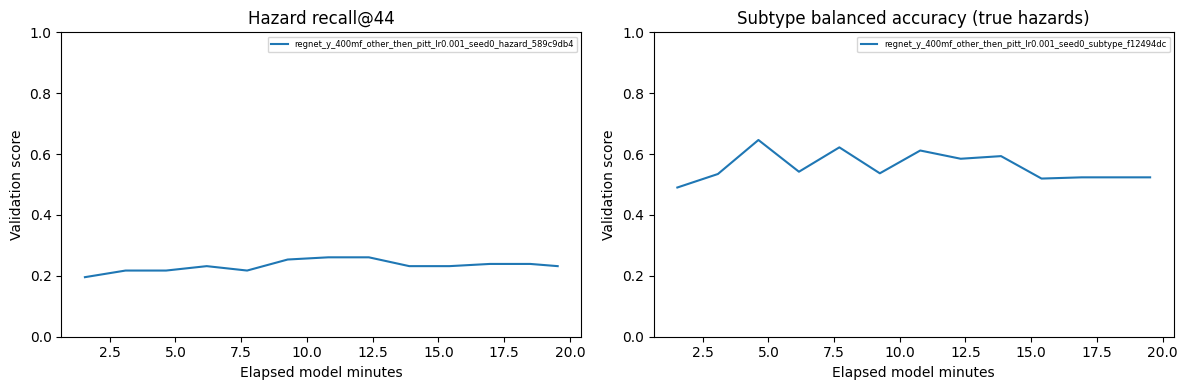

Configuration 0 — rows true, columns predicted


,clean,hazard
clean,145,99
hazard,19,119


,SurfaceProblem,Obstacle
SurfaceProblem,54,70
Obstacle,2,12


,clean,Obstacle,SurfaceProblem
clean,145,40,59
Obstacle,2,10,2
SurfaceProblem,17,63,44


Drive artifacts: /content/drive/MyDrive/MLiP/scratch_classifiers/20261031T022348Z-c27d49


In [19]:
import matplotlib.pyplot as plt
from IPython.display import display

model_table = pd.read_csv(RUN_DIR / 'sweep_results.csv')
display(model_table)
pipeline_table = pd.read_csv(RUN_DIR / 'pipeline_threshold_sweep.csv')
headline = pipeline_table[(pipeline_table.stage1_threshold == 0.5) & (pipeline_table.stage2_threshold == 0.5)]
display(headline[['config_index', 'architecture', 'train', 'lr', 'seed', f's1_recall@{K}',
                  f's1_precision@{K}', 's1_balanced_accuracy', 's2_balanced_accuracy', 'pipeline_accuracy']])
engine.save_csv(RUN_DIR / 'summary.csv', headline)
figures = RUN_DIR / 'figures'
figures.mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for result in completed:
    history = pd.read_csv(Path(result['directory']) / 'history.csv')
    axis = axes[0 if result['task'] == 'hazard' else 1]
    metric = f'recall@{K}' if result['task'] == 'hazard' else 'balanced_accuracy'
    axis.plot(history.elapsed_seconds / 60, history[metric], label=Path(result['directory']).name)
for axis, title in zip(axes, [f'Hazard recall@{K}', 'Subtype balanced accuracy (true hazards)']):
    axis.set(title=title, xlabel='Elapsed model minutes', ylabel='Validation score', ylim=(0, 1))
    axis.legend(fontsize=6)
fig.tight_layout()
fig.savefig(figures / 'validation_learning_curves.png', dpi=160)
plt.show()
for config_index in range(len(CONFIGS)):
    report = pipeline_confusions[f'{config_index}:s1=0.5:s2=0.5']
    print('Configuration', config_index, '— rows true, columns predicted')
    display(pd.DataFrame(report['stage1']['confusion'], index=['clean', 'hazard'], columns=['clean', 'hazard']))
    display(pd.DataFrame(report['stage2']['confusion'], index=['SurfaceProblem', 'Obstacle'], columns=['SurfaceProblem', 'Obstacle']))
    display(pd.DataFrame(report['pipeline_confusion'], index=report['pipeline_classes'], columns=report['pipeline_classes']))
print('Drive artifacts:', RUN_DIR)


## Files saved on Google Drive

- Run level: `run_config.json`, `data_manifest.json`, source CSVs, `dataset_config.yaml`, `training_engine.py`,
  session/package/GPU details, `console.log`, `status.json`, `model_summaries.json`, `sweep_results.csv`,
  `pipeline_threshold_sweep.csv`, `pipeline_confusions.json`, `val_predictions.csv`, `summary.csv`, and figures.
- Per model: `identity.json`, `last.pt` (resume state), `best.pt` (selected model), `progress.json`,
  `history.jsonl`/`history.csv`, `threshold_sweep.csv`, `val_predictions.csv`, and `summary.json`.
- Failure/interruption details are saved when the Python process can handle them. A killed runtime loses work since its last checkpoint.

To resume, reconnect to Colab, set `RESUME_RUN_DIR` to the printed Drive directory, keep the same settings, and Run All.
This notebook does not need the OpenAI API key or access to gated DINO weights; HF_TOKEN is only for the private dataset.
